In [8]:
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Markdown, display
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


In [9]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])

train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
test_dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

SUBSET_SIZE = 10_000
subset_generator = torch.Generator().manual_seed(SEED)
subset_indices = torch.randperm(
    len(train_dataset), generator=subset_generator
)[:SUBSET_SIZE].tolist()
training_subset = torch.utils.data.Subset(train_dataset, subset_indices)

test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False)
train_evaluation_loader = DataLoader(
    training_subset, batch_size=512, shuffle=False
)

print(f"Official training images downloaded: {len(train_dataset):,}")
print(f"Training subset used per experiment: {len(training_subset):,}")
print(f"Testing images: {len(test_dataset):,}")
print(f"Image tensor shape: {train_dataset[0][0].shape}")

Official training images downloaded: 60,000
Training subset used per experiment: 10,000
Testing images: 10,000
Image tensor shape: torch.Size([1, 28, 28])


View ten labeled training examples to confirm the dataset loaded correctly.

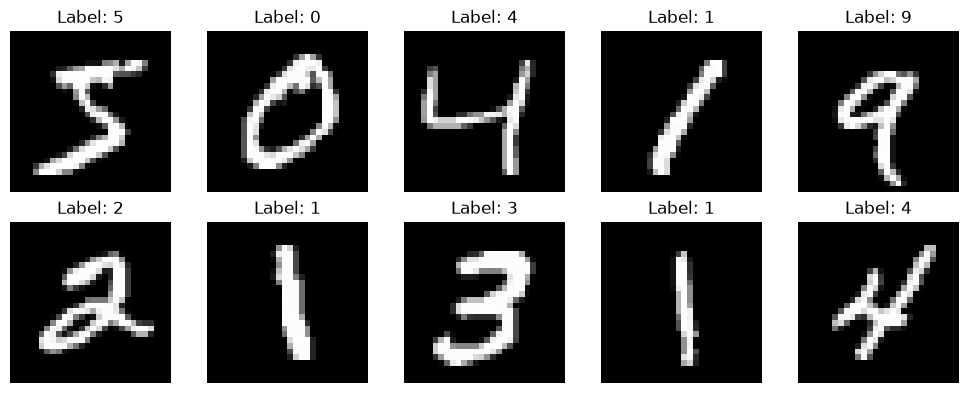

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for index, axis in enumerate(axes.flat):
    image, label = train_dataset[index]
    axis.imshow(image.squeeze(), cmap="gray")
    axis.set_title(f"Label: {label}")
    axis.axis("off")
fig.tight_layout()
plt.show()

Flatten each image into 784 inputs and return raw scores for the ten digit classes.

In [11]:
class MNISTNetwork(nn.Module):
    def __init__(self, dropout_rate=0.2):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(64, 10),
        )

    def forward(self, images):
        return self.layers(images)

print(MNISTNetwork(dropout_rate=0.2))

MNISTNetwork(
  (layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.2, inplace=False)
    (7): Linear(in_features=64, out_features=10, bias=True)
  )
)


Reset the model and optimizer for each run, then measure accuracy on the training subset and held-out test set.

In [12]:
def accuracy_percent(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            predictions = model(images).argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)
    return 100.0 * correct / total


def run_experiment(name, changed_parameter, config):
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    generator = torch.Generator().manual_seed(SEED)
    experiment_train_loader = DataLoader(
        training_subset,
        batch_size=config["batch_size"],
        shuffle=True,
        generator=generator,
    )
    model = MNISTNetwork(dropout_rate=config["dropout_rate"]).to(device)
    loss_function = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=config["learning_rate"],
        weight_decay=config["weight_decay"],
    )

    for epoch in range(config["epochs"]):
        model.train()
        total_loss = 0.0
        for images, labels in experiment_train_loader:
            images = images.to(device)
            labels = labels.to(device)
            optimizer.zero_grad()
            loss = loss_function(model(images), labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * labels.size(0)

        mean_loss = total_loss / len(training_subset)
        print(
            f"{name} | epoch {epoch + 1}/{config['epochs']} "
            f"| training loss: {mean_loss:.4f}"
        )

    train_accuracy = accuracy_percent(model, train_evaluation_loader)
    test_accuracy = accuracy_percent(model, test_loader)
    print(
        f"{name} | training-subset accuracy: {train_accuracy:.2f}% "
        f"| test accuracy: {test_accuracy:.2f}%\n"
    )
    return {
        "run": name,
        "changed_parameter": changed_parameter,
        **config,
        "train_accuracy_percent": train_accuracy,
        "test_accuracy_percent": test_accuracy,
    }

## 6. Run the baseline and five experiments

Run the baseline cell first, then execute each experiment cell in order. Each experiment changes one setting from the baseline.

In [13]:
baseline = {
    "learning_rate": 0.001,
    "epochs": 2,
    "batch_size": 64,
    "dropout_rate": 0.2,
    "weight_decay": 0.0001,
}

results = [run_experiment("Baseline", "none", baseline.copy())]

Baseline | epoch 1/2 | training loss: 0.7488
Baseline | epoch 2/2 | training loss: 0.3392
Baseline | training-subset accuracy: 93.13% | test accuracy: 92.47%



### Number of epochs

Change the epoch count from 2 to 3.

In [14]:
config = baseline.copy()
config["epochs"] = 3
results.append(run_experiment("More epochs", "epochs", config))

More epochs | epoch 1/3 | training loss: 0.7488
More epochs | epoch 2/3 | training loss: 0.3392
More epochs | epoch 3/3 | training loss: 0.2566
More epochs | training-subset accuracy: 95.30% | test accuracy: 93.66%



### Learning rate

Lower the learning rate from 0.001 to 0.0005.

In [15]:
config = baseline.copy()
config["learning_rate"] = 0.0005
results.append(run_experiment("Lower learning rate", "learning_rate", config))

Lower learning rate | epoch 1/2 | training loss: 0.9405
Lower learning rate | epoch 2/2 | training loss: 0.4192
Lower learning rate | training-subset accuracy: 92.35% | test accuracy: 91.38%



### Batch size

Increase the batch size from 64 to 128.

In [16]:
config = baseline.copy()
config["batch_size"] = 128
results.append(run_experiment("Larger batch", "batch_size", config))

Larger batch | epoch 1/2 | training loss: 0.9149
Larger batch | epoch 2/2 | training loss: 0.3961
Larger batch | training-subset accuracy: 92.62% | test accuracy: 91.98%



### Dropout rate

Increase dropout from 0.2 to 0.4.

In [17]:
config = baseline.copy()
config["dropout_rate"] = 0.4
results.append(run_experiment("More dropout", "dropout_rate", config))

More dropout | epoch 1/2 | training loss: 0.9679
More dropout | epoch 2/2 | training loss: 0.4729
More dropout | training-subset accuracy: 92.39% | test accuracy: 91.84%



### Weight decay

Increase weight decay from 0.0001 to 0.001.

In [18]:
config = baseline.copy()
config["weight_decay"] = 0.001
results.append(run_experiment("More weight decay", "weight_decay", config))

More weight decay | epoch 1/2 | training loss: 0.7504
More weight decay | epoch 2/2 | training loss: 0.3460
More weight decay | training-subset accuracy: 93.01% | test accuracy: 92.17%



Compare parameter settings and select the best run by test accuracy.

In [19]:
table_lines = [
    "| Run | Changed parameter | Learning rate | Epochs | Batch size | Dropout | Weight decay | Train-subset accuracy | Test accuracy |",
    "|---|---|---:|---:|---:|---:|---:|---:|---:|",
]
for result in results:
    table_lines.append(
        f"| {result['run']} | {result['changed_parameter']} "
        f"| {result['learning_rate']:.6f} | {result['epochs']} "
        f"| {result['batch_size']} | {result['dropout_rate']:.2f} "
        f"| {result['weight_decay']:.6f} "
        f"| {result['train_accuracy_percent']:.2f}% "
        f"| {result['test_accuracy_percent']:.2f}% |"
    )
display(Markdown("\n".join(table_lines)))

best_result = max(results, key=lambda result: result["test_accuracy_percent"])
print(
    f"Highest test accuracy: {best_result['test_accuracy_percent']:.2f}% "
    f"({best_result['run']})"
)
print(
    "Best settings: "
    f"learning rate={best_result['learning_rate']}, "
    f"epochs={int(best_result['epochs'])}, "
    f"batch size={int(best_result['batch_size'])}, "
    f"dropout={best_result['dropout_rate']}, "
    f"weight decay={best_result['weight_decay']}"
)

| Run | Changed parameter | Learning rate | Epochs | Batch size | Dropout | Weight decay | Train-subset accuracy | Test accuracy |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| Baseline | none | 0.001000 | 2 | 64 | 0.20 | 0.000100 | 93.13% | 92.47% |
| More epochs | epochs | 0.001000 | 3 | 64 | 0.20 | 0.000100 | 95.30% | 93.66% |
| Lower learning rate | learning_rate | 0.000500 | 2 | 64 | 0.20 | 0.000100 | 92.35% | 91.38% |
| Larger batch | batch_size | 0.001000 | 2 | 128 | 0.20 | 0.000100 | 92.62% | 91.98% |
| More dropout | dropout_rate | 0.001000 | 2 | 64 | 0.40 | 0.000100 | 92.39% | 91.84% |
| More weight decay | weight_decay | 0.001000 | 2 | 64 | 0.20 | 0.001000 | 93.01% | 92.17% |

Highest test accuracy: 93.66% (More epochs)
Best settings: learning rate=0.001, epochs=3, batch size=64, dropout=0.2, weight decay=0.0001


## 8. Reflection

Each experiment changed one setting from the baseline:

- **Epochs (2 to 3):** training accuracy increased from 93.13% to 95.30%, and test accuracy increased from 92.47% to 93.66%.
- **Learning rate (0.001 to 0.0005):** training accuracy decreased from 93.13% to 92.35%, and test accuracy decreased from 92.47% to 91.38%.
- **Batch size (64 to 128):** training accuracy decreased from 93.13% to 92.62%, and test accuracy decreased from 92.47% to 91.98%.
- **Dropout (0.2 to 0.4):** training accuracy decreased from 93.13% to 92.39%, and test accuracy decreased from 92.47% to 91.84%.
- **Weight decay (0.0001 to 0.001):** training accuracy decreased from 93.13% to 93.01%, and test accuracy decreased from 92.47% to 92.17%.

### Best configuration and model fit

The highest test accuracy was **93.66%**, achieved with a learning rate of 0.001, 3 epochs, batch size 64, dropout 0.2, and weight decay 0.0001. The training accuracy was 95.30%, a 1.64 percentage-point gap from test accuracy. These results do not suggest underfitting or a large overfitting gap.

### What I would try next

I would repeat the best settings with several random seeds, then compare them on a validation split before using the test set for a final check. I would also compare this fully connected network with a small convolutional network.